Loading YOLO26-Nano model: yolo26n-seg.pt
Using device for YOLO inference: mps

EVALUATING MODEL: YOLO26-Nano

--- Quantitative Results: YOLO26-Nano ---
* Valid Samples Evaluated : 100
* Model Parameters        : ~3.13 M
* Avg Latency             : 69.69 ms
* Median Latency          : 40.97 ms
* Average FPS             : 14.35
* Pixel Accuracy          : 34.43%
* Mean IoU (mIoU)         : 2.45%
----------------------------------------------


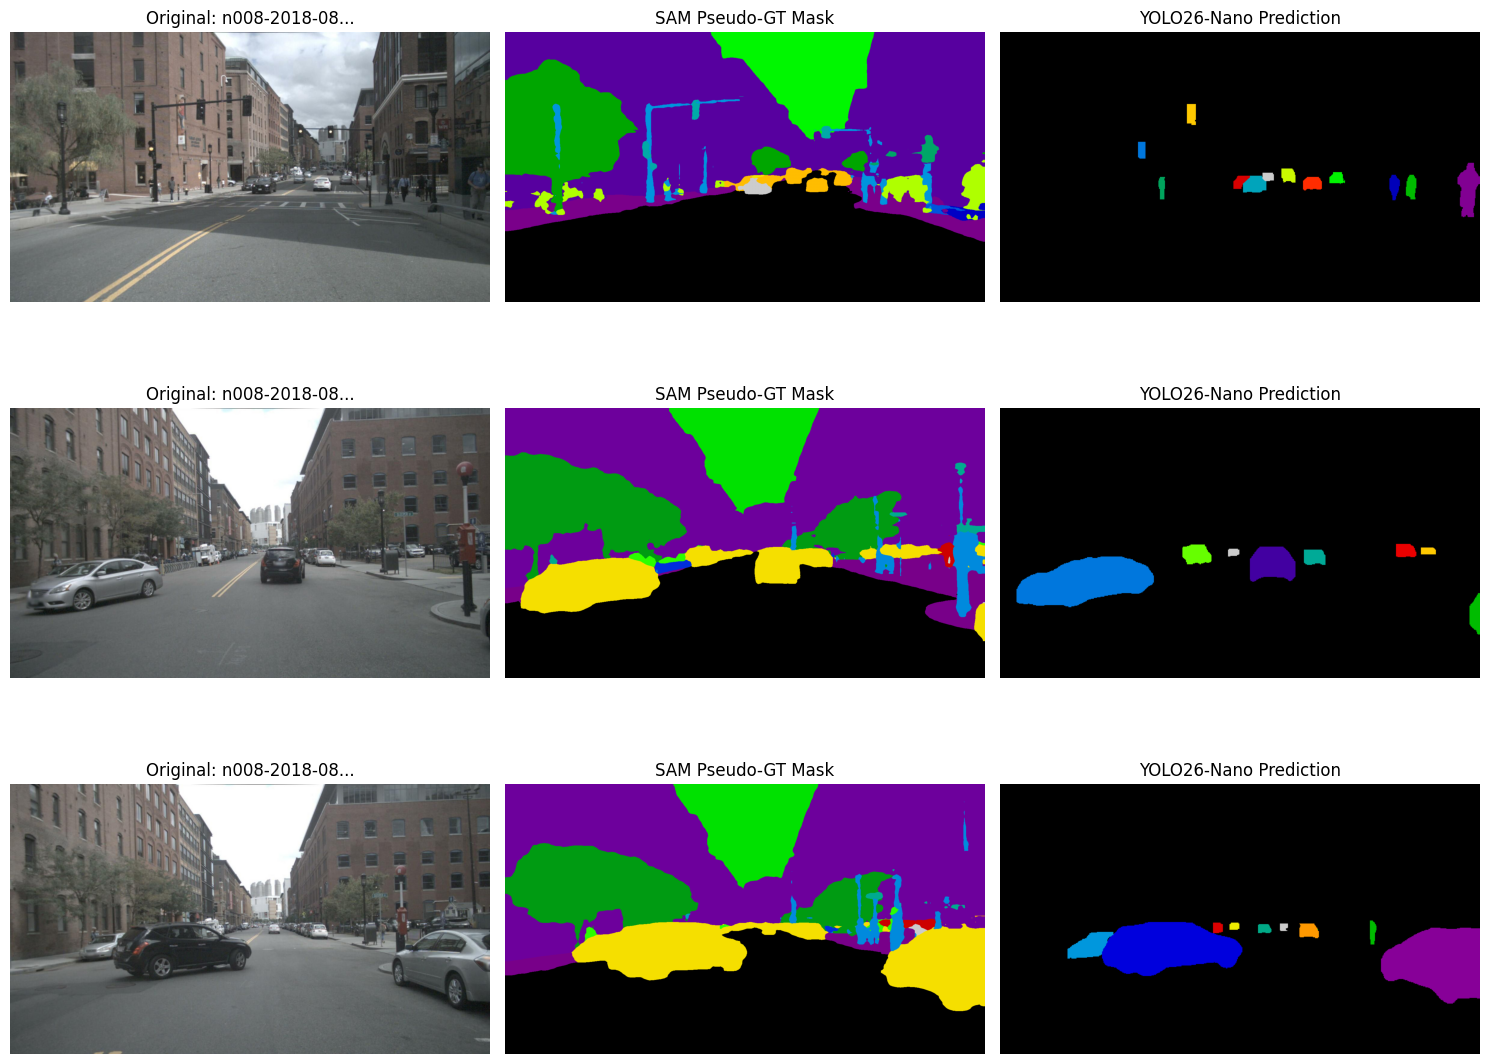

In [1]:
import time
import random
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from ultralytics import YOLO

# 0. Environment & Path Setup
cam_front_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/v1.0-mini/samples/CAM_FRONT/")
benchmark_images = sorted(list(cam_front_dir.glob("*.jpg")))[:100]
gt_output_dir = Path("/Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/results/pseudo_ground_truth")

# 1. Load Pretrained YOLO26-Nano Segmentation Model
model_name_yolo = "yolo26n-seg.pt"
print(f"Loading YOLO26-Nano model: {model_name_yolo}")
yolo_model = YOLO(model_name_yolo)

# Automatically assign device (MPS for Apple Silicon or CPU fallback)
device = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using device for YOLO inference: {device}")

# 2. Comprehensive Evaluation & Visualization Function for YOLO26
def evaluate_and_visualize_yolo(
    model_name, 
    model, 
    image_paths, 
    gt_dir, 
    device, 
    num_classes=19
):
    latencies = []
    confusion_matrix = np.zeros((num_classes, num_classes))
    valid_samples = []

    print(f"\n==============================================")
    print(f"EVALUATING MODEL: {model_name}")
    print(f"==============================================")

    # Estimate parameter count safely from the underlying model architecture
    try:
        total_params = sum(p.numel() for p in model.model.parameters()) / 1e6
    except Exception:
        total_params = 3.2  # Standard approximate baseline for nano-seg variants

    for img_path in image_paths:
        mask_path = gt_dir / f"{img_path.stem}_mask.png"
        if not mask_path.exists():
            mask_path = gt_dir / f"{img_path.stem}.png"
            if not mask_path.exists():
                continue
        
        image = Image.open(img_path).convert("RGB")
        orig_size = image.size 
        gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)
        
        # Measure inference latency
        start_time = time.time()
        results = model.predict(source=str(img_path), device=device, verbose=False)
        
        if device == "mps":
            torch.mps.synchronize()
        elif device == "cuda":
            torch.cuda.synchronize()
            
        elapsed = time.time() - start_time
        latencies.append(elapsed)

        # Extract segmentation mask output
        res = results[0]
        if res.masks is not None and len(res.masks.data) > 0:
            masks_data = res.masks.data.cpu().numpy()
            combined_pred = np.zeros((orig_size[1], orig_size[0]), dtype=np.uint8)
            for i, m in enumerate(masks_data):
                resized_m = cv2.resize(m, (orig_size[0], orig_size[1]), interpolation=cv2.INTER_NEAREST)
                combined_pred[resized_m > 0.5] = (i % (num_classes - 1)) + 1
            pred = combined_pred
        else:
            pred = np.zeros((orig_size[1], orig_size[0]), dtype=np.uint8)

        if pred.shape != gt_mask.shape:
            gt_mask = np.array(
                Image.fromarray(gt_mask.astype(np.uint8)).resize(
                    (pred.shape[1], pred.shape[0]), Image.NEAREST
                )
            )

        mask = (gt_mask >= 0) & (gt_mask < num_classes)
        confusion_matrix += np.bincount(
            num_classes * gt_mask[mask].astype(int) + pred[mask].astype(int),
            minlength=num_classes ** 2,
        ).reshape(num_classes, num_classes)

        valid_samples.append((img_path, gt_mask, pred))

    if not latencies:
        print("[Error] No matching ground truth masks found for YOLO evaluation.")
        return None

    avg_lat = np.array(latencies).mean()
    med_lat = np.median(np.array(latencies))
    avg_fps = 1.0 / avg_lat

    intersection = np.diag(confusion_matrix)
    union = confusion_matrix.sum(axis=1) + confusion_matrix.sum(axis=0) - intersection
    per_class_iou = np.divide(
        intersection, union, out=np.zeros_like(intersection, dtype=float), where=union != 0
    )
    mIoU = np.nanmean(per_class_iou)

    total_correct = np.sum(intersection)
    total_pixels = np.sum(confusion_matrix)
    pixel_accuracy = (total_correct / total_pixels) if total_pixels > 0 else 0.0

    print(f"\n--- Quantitative Results: {model_name} ---")
    print(f"* Valid Samples Evaluated : {len(valid_samples)}")
    print(f"* Model Parameters        : ~{total_params:.2f} M")
    print(f"* Avg Latency             : {avg_lat * 1000:.2f} ms")
    print(f"* Median Latency          : {med_lat * 1000:.2f} ms")
    print(f"* Average FPS             : {avg_fps:.2f}")
    print(f"* Pixel Accuracy          : {pixel_accuracy * 100:.2f}%")
    print(f"* Mean IoU (mIoU)         : {mIoU * 100:.2f}%")
    print(f"----------------------------------------------")

    if valid_samples:
        viz_samples = random.sample(valid_samples, min(3, len(valid_samples)))
        fig, axes = plt.subplots(len(viz_samples), 3, figsize=(15, 4 * len(viz_samples)))
        
        if len(viz_samples) == 1:
            axes = np.expand_dims(axes, 0)

        for idx, (img_p, gt, pred) in enumerate(viz_samples):
            orig_img = cv2.cvtColor(cv2.imread(str(img_p)), cv2.COLOR_BGR2RGB)

            axes[idx, 0].imshow(orig_img)
            axes[idx, 0].set_title(f"Original: {img_p.name[:12]}...")
            axes[idx, 0].axis("off")

            axes[idx, 1].imshow(gt, cmap="nipy_spectral")
            axes[idx, 1].set_title("SAM Pseudo-GT Mask")
            axes[idx, 1].axis("off")

            axes[idx, 2].imshow(pred, cmap="nipy_spectral")
            axes[idx, 2].set_title(f"{model_name} Prediction")
            axes[idx, 2].axis("off")

        plt.tight_layout()
        plt.show()

    return {
        "Model": model_name,
        "Params (M)": round(total_params, 2),
        "Avg Latency (ms)": round(avg_lat * 1000, 2),
        "FPS": round(avg_fps, 2),
        "Pixel Acc (%)": round(pixel_accuracy * 100, 2),
        "mIoU (%)": round(mIoU * 100, 2)
    }

# 3. Run Execution Pipeline
yolo_metrics = evaluate_and_visualize_yolo(
    model_name="YOLO26-Nano",
    model=yolo_model,
    image_paths=benchmark_images,
    gt_dir=gt_output_dir,
    device=device
)